# Part II — Linear regression: how many places is a grid slot worth?
**Method (sessions 2–5):** linear regression, least squares, Ridge and Lasso, cross-validation.
**Why first:** it is the simplest model and every coefficient is a sentence: *"one place further back on the grid costs X places at the finish"*.
**Target:** finishing position of classified drivers. **Train:** 2010–2024. **Test:** 2025 and 2026 (never seen).

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
c = d[d.finish_pos.notna()].copy(); c['log_grid'] = np.log(c.grid)
train, tests = c[c.year <= 2024], {y: c[c.year == y] for y in (2025, 2026)}

### Step 1 — one variable: the grid

In [2]:
m = LinearRegression().fit(train[['grid']], train.finish_pos)
print(f"finish = {m.intercept_:.2f} + {m.coef_[0]:.2f} x grid")
print(f"=> one place further back on the grid costs {m.coef_[0]:.2f} places at the finish, on average.")

finish = 2.48 + 0.65 x grid
=> one place further back on the grid costs 0.65 places at the finish, on average.


### Step 2 — add what we know about the car and the driver, and regularise (Ridge / Lasso, alpha chosen by 5-fold cross-validation grouped by season)

In [3]:
FEATS = ['grid', 'log_grid', 'quali_gap', 'practice_gap', 'team_points', 'team_avg_finish', 'team_mech_dnf', 'drv_avg_finish']
cv = list(GroupKFold(5).split(train, groups=train.year))
models = {
    'Baseline: finish = grid': None,
    'Linear, grid only': make_pipeline(StandardScaler(), LinearRegression()),
    'Linear, extended (8 variables)': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge, extended': make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25), cv=cv)),
    'Lasso, extended': make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-3, 0, 25), cv=cv, random_state=0)),
}
rows = []
for name, m in models.items():
    f = ['grid'] if name == 'Linear, grid only' else FEATS
    if m is not None: m.fit(train[f], train.finish_pos)
    for y, t in tests.items():
        p = t.grid.values if m is None else m.predict(t[f])
        rows.append({'Model': name, 'Test': y, 'MAE': mean_absolute_error(t.finish_pos, p),
                     'RMSE': mean_squared_error(t.finish_pos, p) ** 0.5, 'R2': r2_score(t.finish_pos, p)})
res = pd.DataFrame(rows).pivot(index='Model', columns='Test', values=['MAE', 'R2']).round(3)
res.loc[list(models)]

MAE            R2       
Test                             2025   2026   2025   2026
Model                                                     
Baseline: finish = grid         2.887  2.884  0.365  0.362
Linear, grid only               2.659  2.604  0.545  0.576
Linear, extended (8 variables)  2.555  2.326  0.585  0.634
Ridge, extended                 2.558  2.325  0.585  0.635
Lasso, extended                 2.556  2.326  0.585  0.634

In [4]:
ridge = models['Ridge, extended']; lasso = models['Lasso, extended']
coef = pd.DataFrame({'Ridge': ridge[-1].coef_, 'Lasso': lasso[-1].coef_}, index=FEATS).round(2)
print('Chosen alpha  Ridge:', round(ridge[-1].alpha_, 3), '| Lasso:', round(lasso[-1].alpha_, 4))
coef.sort_values('Ridge', key=abs, ascending=False)

Chosen alpha  Ridge: 31.623 | Lasso: 0.0032


,Ridge,Lasso
grid,1.64,1.70
team_avg_finish,1.07,1.10
practice_gap,0.77,0.77
drv_avg_finish,0.63,0.62
log_grid,0.51,0.47
team_mech_dnf,-0.35,-0.35
team_points,-0.33,-0.32
quali_gap,0.05,0.02


### Step 3 — the grid effect is not a straight line, especially at the front

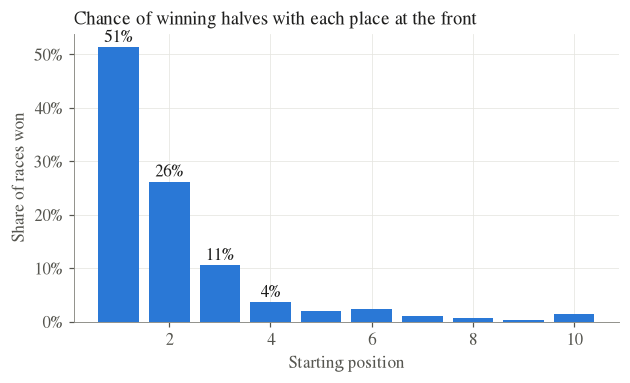

R² on train with ['grid']: 0.571
R² on train with ['grid', 'log_grid']: 0.577


In [5]:
win_rate = d[d.year <= 2024].groupby(d.grid.clip(upper=20)).win.mean()
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(win_rate.index[:10], win_rate.values[:10], color=BLUE)
for g, v in win_rate.head(4).items(): ax.text(g, v + 0.01, f"{v:.0%}", ha='center', color=INK)
ax.set_xlabel('Starting position'); ax.set_ylabel('Share of races won'); ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
title(ax, 'Chance of winning halves with each place at the front'); save(fig, '02_win_by_grid'); plt.show()
for f in (['grid'], ['grid', 'log_grid']):
    print(f"R² on train with {f}: {LinearRegression().fit(train[f], train.finish_pos).score(train[f], train.finish_pos):.3f}")

### What we learn (and carry to the next parts)
1. **One grid place is worth about 0.65 finishing places.** The grid alone explains more than half of the finishing order (R² ≈ 0.55 on the test seasons).
2. **Adding car and qualifying information lowers the error** below the "finish = grid" baseline on both test seasons.
3. **Ridge and Lasso keep almost the same coefficients:** with 8 features and thousands of rows, there is little overfitting to fix.
4. **The grid effect bends:** pole wins 52% of races, 2nd 24%, 3rd 11%. Each place at the front halves the chance of winning, which no straight line can follow. Adding `log(grid)` next to `grid` captures this curve (R² 0.550 → 0.561 for finishing position, and much more for the winner in Part V), so from now on every model gets both.
5. **The car matters:** team strength features are among the largest coefficients. Part III summarises them properly.